In [1]:
import numpy as np
import pandas as pd


In [2]:
customer=pd.read_csv("Customer.csv")

In [3]:
products=pd.read_csv("prod_cat_info.csv")

In [4]:
transaction=pd.read_csv("Transactions.csv")
transaction.head()

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type
0,80712190438,270351,28-02-2014,1,1,-5,-772,405.300,-4265.300,e-Shop
1,29258453508,270384,27-02-2014,5,3,-5,-1497,785.925,-8270.925,e-Shop
2,51750724947,273420,24-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop
3,93274880719,271509,24-02-2014,11,6,-3,-1363,429.345,-4518.345,e-Shop
4,51750724947,273420,23-02-2014,6,5,-2,-791,166.110,-1748.110,TeleShop


In [5]:
print(f'customer table has rows: {customer.shape[0]} and columns are: {customer.shape[1]}')

print('Number of Null values in each column of Customer table')
print(customer.isna().sum())
print('duplicate values')
print(customer.duplicated().sum())
print(customer.Gender.unique())

customer.info()       # dob has object data type instead of date

customer table has rows: 5647 and columns are: 4
Number of Null values in each column of Customer table
customer_Id    0
DOB            0
Gender         2
city_code      2
dtype: int64
duplicate values
0
['M' 'F' nan]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5647 entries, 0 to 5646
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   customer_Id  5647 non-null   int64  
 1   DOB          5647 non-null   object 
 2   Gender       5645 non-null   object 
 3   city_code    5645 non-null   float64
dtypes: float64(1), int64(1), object(2)
memory usage: 176.6+ KB


In [6]:
for col in customer.select_dtypes(customer.dtypes):
    print(f'{col:<14}: {customer[col].unique()}')

customer_Id   : [268408 269696 268159 ... 270476 269626 274308]
DOB           : ['02-01-1970' '07-01-1970' '08-01-1970' ... '25-12-1992' '27-12-1992'
 '29-12-1992']
Gender        : ['M' 'F' nan]
city_code     : [ 4.  8.  2.  1.  5.  9.  7. 10.  6.  3. nan]


In [7]:
for col in customer.columns:
    print(f'{col:<14}: {products.duplicated().sum()}')

customer_Id   : 0
DOB           : 0
Gender        : 0
city_code     : 0


In [8]:
print(f'shape is:{products.shape}')

print('Number of Null values in each column of products table')
print(products.isna().sum())

print(f'duplicates : {products.duplicated().sum()}')

print(products.info())

print(products.describe())

shape is:(23, 4)
Number of Null values in each column of products table
prod_cat_code        0
prod_cat             0
prod_sub_cat_code    0
prod_subcat          0
dtype: int64
duplicates : 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   prod_cat_code      23 non-null     int64 
 1   prod_cat           23 non-null     object
 2   prod_sub_cat_code  23 non-null     int64 
 3   prod_subcat        23 non-null     object
dtypes: int64(2), object(2)
memory usage: 868.0+ bytes
None
       prod_cat_code  prod_sub_cat_code
count      23.000000          23.000000
mean        3.739130           6.130435
std         1.711389           3.805550
min         1.000000           1.000000
25%         2.500000           3.000000
50%         4.000000           5.000000
75%         5.000000          10.000000
max         6.000000          12.000000


In [9]:
print(f'transaction table has rows: {transaction.shape[0]} and columns are: {transaction.shape[1]}')
print('Number of Null values in each column of transaction table')
print(transaction.isna().sum())
print(f'duplicated are :{transaction.duplicated().sum()}')

transaction table has rows: 23053 and columns are: 10
Number of Null values in each column of transaction table
transaction_id      0
cust_id             0
tran_date           0
prod_subcat_code    0
prod_cat_code       0
Qty                 0
Rate                0
Tax                 0
total_amt           0
Store_type          0
dtype: int64
duplicated are :13


In [10]:
transaction.drop_duplicates(inplace=True)   # we drop 13 rows because 13/23040~~0.00005

In [11]:
transaction.info()         # tran_date is object instead of date

<class 'pandas.core.frame.DataFrame'>
Index: 23040 entries, 0 to 23052
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    23040 non-null  int64  
 1   cust_id           23040 non-null  int64  
 2   tran_date         23040 non-null  object 
 3   prod_subcat_code  23040 non-null  int64  
 4   prod_cat_code     23040 non-null  int64  
 5   Qty               23040 non-null  int64  
 6   Rate              23040 non-null  int64  
 7   Tax               23040 non-null  float64
 8   total_amt         23040 non-null  float64
 9   Store_type        23040 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.9+ MB


In [12]:
transaction.describe()

,transaction_id,cust_id,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt
count,2.304000e+04,23040.000000,23040.000000,23040.000000,23040.000000,23040.000000,23040.000000,23040.000000
mean,5.006955e+10,271021.880252,6.148785,3.763498,2.435764,637.094965,248.677488,2109.865226
std,2.898062e+10,2431.573668,3.726197,1.677091,2.264326,621.727374,187.188311,2505.610295
min,3.268991e+06,266783.000000,1.000000,1.000000,-5.000000,-1499.000000,7.350000,-8270.925000
25%,2.493315e+10,268935.000000,3.000000,2.000000,1.000000,312.000000,98.280000,762.450000
50%,5.009188e+10,270980.500000,5.000000,4.000000,3.000000,710.000000,199.080000,1756.950000
75%,7.532632e+10,273114.250000,10.000000,5.000000,4.000000,1109.000000,365.767500,3570.255000
max,9.998755e+10,275265.000000,12.000000,6.000000,5.000000,1500.000000,787.500000,8287.500000


In [13]:
# check whether there are any customer_id present in orders table which are not in customer table

invalid_customers=transaction[~transaction.cust_id.isin(customer['customer_Id'])]
print(len(invalid_customers))

0


# convert string dates to actual dates

In [14]:
transaction['tran_date']=pd.to_datetime(transaction.tran_date,format='mixed',dayfirst=True)

# Challenge 1: The Phantom Transactions
### we need to check if there is only problem with total_amt or qty is also negative, this will indicate they are returns

In [15]:
transaction[(transaction.total_amt<0 ) & (transaction.Qty>0)]
# these negative values represents returns only
# How widespread is this issue
print(f'total records with return: {(transaction.total_amt<0).sum()}')
total_records=len(transaction.transaction_id)
rate=((transaction.total_amt<0).sum()*100/total_records).round(2)
print(f'{rate}%')

total records with return: 2164
9.39%


# Challenge 2: How Far Back Does Our Memory Go?
 ### How many years of purchase behaviour can we actually draw on?

In [16]:
from datetime import datetime as dt

mini = transaction.tran_date.min()
maxi = transaction.tran_date.max()

time_difference = (maxi - mini).days//365

print(f'transactional data is over : {time_difference} years')

transactional data is over : 3 years


###  Are we looking at one year of data or five? 3 years of date
Can we compare this January to last January?'

In [17]:
monthly=transaction.groupby(transaction.tran_date.dt.to_period('M'))['total_amt'].sum().reset_index()
monthly

,tran_date,total_amt
0,2011-01,337307.880
1,2011-02,1087283.535
2,2011-03,1376537.175
3,2011-04,1379838.915
4,2011-05,1174157.530
5,2011-06,1226771.000
6,2011-07,1310933.325
7,2011-08,1230637.395
8,2011-09,1437136.480
9,2011-10,1399860.410


-3.188277374495875


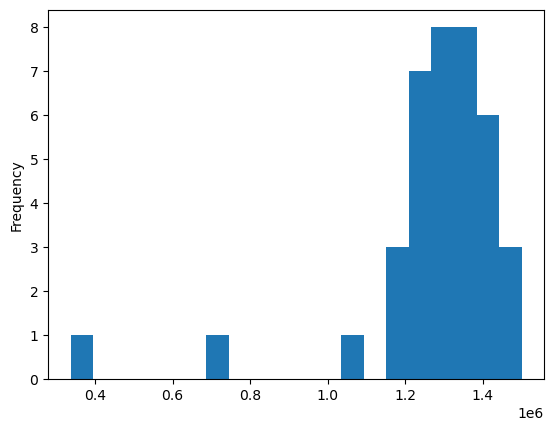

In [9]:
# Statistical distribution
monthly["total_amt"].plot(
    kind="hist",
    bins=20
)

print(monthly["total_amt"].skew())

In [11]:
pd.pivot_table(transaction,values='total_amt',index=transaction.tran_date.dt.year,columns=transaction.tran_date.dt.month).rename(index={'tran_date':'year'})

tran_date,1,2,3,4,5,6,7,8,9,10,11,12
tran_date,,,,,,,,,,,,
2011,2392.254468,1931.231856,2121.012596,2265.745345,2007.106889,2112.974118,1968.872383,1938.011646,2151.401916,2207.981719,2288.432342,2106.970151
2012,2012.392850,2152.722043,2279.046764,1835.070658,2043.942405,2281.686875,2057.185429,2114.061248,2115.028531,2092.132786,2097.873615,2256.812938
2013,2260.065557,2192.167936,2194.051939,2155.436892,2091.137935,2059.620205,1950.511810,2130.662348,2093.304045,2039.624151,2144.271166,1989.115396
2014,2200.241327,1919.263825,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#  city-level concentration 
analysis to inform a new store location decision.

In [18]:
merge_table=pd.merge(left=customer,right=transaction,how='inner',left_on=customer.customer_Id,right_on=transaction.cust_id)


In [22]:
merge_table.groupby('city_code')[['customer_Id','Store_type']].agg({'customer_Id':'nunique','Store_type':'nunique'}).sort_values(by='customer_Id').reset_index()

,city_code,customer_Id,Store_type
0,6.0,516,4
1,9.0,532,4
2,1.0,535,4
3,2.0,546,4
4,10.0,546,4
5,8.0,551,4
6,7.0,563,4
7,4.0,569,4
8,5.0,570,4
9,3.0,576,4


# Challenge 4: Who Buys What? Gender and Category Preferences

In [25]:
customer['actual_dob']=pd.to_datetime(customer.DOB,dayfirst=True)

In [26]:
customer

,customer_Id,DOB,Gender,city_code,actual_dob
0,268408,02-01-1970,M,4.0,1970-01-02
1,269696,07-01-1970,F,8.0,1970-01-07
2,268159,08-01-1970,F,8.0,1970-01-08
3,270181,10-01-1970,F,2.0,1970-01-10
4,268073,11-01-1970,M,1.0,1970-01-11
...,...,...,...,...,...
5642,274474,19-12-1992,M,2.0,1992-12-19
5643,267666,24-12-1992,M,6.0,1992-12-24
5644,270476,25-12-1992,F,3.0,1992-12-25
5645,269626,27-12-1992,F,5.0,1992-12-27


In [8]:
cust_tran=pd.merge(left=customer,right=transaction,how='inner',left_on=customer.customer_Id,right_on=transaction.cust_id)


In [9]:
category_data=cust_tran.pivot_table(index='prod_cat_code',columns='Gender',values=['total_amt'],aggfunc='sum')
category_data

total_amt             
Gender                   F            M
prod_cat_code                          
1              3026750.805  3224079.495
2              3202552.990  3014672.050
3              5019354.210  5703109.425
4              2077985.650  2046722.990
5              6164692.235  6645972.775
6              4132177.335  4301075.480

In [10]:
# it counts the number of items purchased by female and male among different product categories
data=pd.crosstab(index=cust_tran.prod_cat_code,columns=cust_tran.Gender)
data

Gender,F,M
prod_cat_code,,
1,1439,1518
2,1529,1469
3,2328,2570
4,994,1004
5,2949,3116
6,1994,2134


In [15]:
total_category=category_data.sum(axis=1)

In [13]:
percentage_table=(category_data.div(total_category,axis=0)*100).round(2).astype(str)+'%'
percentage_table

total_amt        
Gender                F       M
prod_cat_code                  
1                48.42%  51.58%
2                51.51%  48.49%
3                46.81%  53.19%
4                50.38%  49.62%
5                48.12%  51.88%
6                 49.0%   51.0%

#  Volume vs Value — Which Store Format Wins on Each?

In [34]:
products_with_actual_purchase=transaction[transaction.total_amt>0]

In [36]:
summ1=products_with_actual_purchase.groupby('Store_type')[['Qty','total_amt']].agg({'Qty':'sum','total_amt':'sum'}).sort_values(by='Qty',ascending=False)

In [50]:
percent_of_eshop=summ1['Qty'][1]/summ1.Qty.sum(axis=0)*100
print(round(percent_of_eshop,2))

20.07


C:\Users\tripa\AppData\Local\Temp\ipykernel_39360\146415723.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  percent_of_eshop=summ1['Qty'][1]/summ1.Qty.sum(axis=0)*100


# Challenge 6: Flagship Revenue Deep-Dive 

In [16]:
tran_products=pd.merge(left=transaction,right=products,how='inner',left_on=['prod_cat_code','prod_subcat_code'],right_on=['prod_cat_code','prod_sub_cat_code'])

In [17]:
filtered=tran_products.loc[((tran_products['prod_cat']=='Clothing') | (tran_products['prod_cat']=='Electronics'))& (tran_products['Store_type']=='Flagship store')]

In [18]:
flagship=filtered.groupby(['prod_cat'])['total_amt'].sum().reset_index()
flagship

,prod_cat,total_amt
0,Clothing,1194423.23
1,Electronics,2215136.04


In [19]:
all_stores=tran_products.loc[((tran_products['prod_cat']=='Clothing') | (tran_products['prod_cat']=='Electronics'))]

In [20]:
total_stores=all_stores.groupby(['prod_cat'])['total_amt'].sum().reset_index()
total_stores

,prod_cat,total_amt
0,Clothing,6.251137e+06
1,Electronics,1.072246e+07


### making new table 

In [71]:
comparsion=flagship.merge(total_stores,on='prod_cat',suffixes=('_flagship', '_all_stores'))
comparsion['percentage']=((comparsion.total_amt_flagship/comparsion.total_amt_all_stores)*100).round(1).astype(str)+'%'

In [72]:
comparsion

,prod_cat,total_amt_flagship,total_amt_all_stores,percentage
0,Clothing,1194423.23,6.251137e+06,19.1%
1,Electronics,2215136.04,1.072246e+07,20.7%


# Challenge 7: The Electronics-Male Segment 

In [80]:
all_3_tables = pd.merge(
    cust_tran,
    products,
    how='inner',
    left_on=['prod_cat_code', 'prod_subcat_code'],
    right_on=['prod_cat_code', 'prod_sub_cat_code']
)


In [81]:
electronics=all_3_tables[all_3_tables.prod_cat=='Electronics']


In [82]:
summ=electronics.groupby(['prod_cat','Gender'])['total_amt'].sum().reset_index()

In [83]:
summ

,prod_cat,Gender,total_amt
0,Electronics,F,5019354.210
1,Electronics,M,5703109.425


In [84]:
summ['share(%)']=((summ['total_amt']/summ['total_amt'].sum())*100).round(1)

In [85]:
summ           # male portion is 53.2% overall revenue

,prod_cat,Gender,total_amt,share(%)
0,Electronics,F,5019354.210,46.8
1,Electronics,M,5703109.425,53.2


# Challenge 8: The Loyal Customers — Who Keeps Coming Back?

In [86]:
transaction_without_return=transaction.loc[transaction.total_amt>0]
transaction_without_return

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type
10,29258453508,270384,20-02-2014,5,3,5,1497,785.925,8270.925,e-Shop
11,25455265351,267750,20-02-2014,12,6,3,1360,428.400,4508.400,e-Shop
12,1571002198,275023,20-02-2014,6,5,4,587,246.540,2594.540,e-Shop
14,36554696014,269345,20-02-2014,3,5,3,1253,394.695,4153.695,e-Shop
15,56814940239,268799,20-02-2014,7,5,5,368,193.200,2033.200,e-Shop
...,...,...,...,...,...,...,...,...,...,...
23048,94340757522,274550,25-01-2011,12,5,1,1264,132.720,1396.720,e-Shop
23049,89780862956,270022,25-01-2011,4,1,1,677,71.085,748.085,e-Shop
23050,85115299378,271020,25-01-2011,2,6,4,1052,441.840,4649.840,MBR
23051,72870271171,270911,25-01-2011,11,5,3,1142,359.730,3785.730,TeleShop


In [87]:
cust_with_morethan_10_orders=transaction_without_return.groupby('cust_id')['tran_date'].count()

In [88]:
cust_with_morethan_10_orders[cust_with_morethan_10_orders>10].reset_index()

,cust_id,tran_date
0,266794,11
1,270535,11
2,270803,11
3,272741,11
4,273014,11
5,274227,11


In [89]:
print(cust_with_morethan_10_orders[cust_with_morethan_10_orders>10].index)

Index([266794, 270535, 270803, 272741, 273014, 274227], dtype='int64', name='cust_id')


# Challenge 9: The 25–35 Cohort — Category Spending Profile

In [90]:
all_3_tables

,key_0,customer_Id,DOB,Gender,city_code,actual_dob,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,prod_cat,prod_sub_cat_code,prod_subcat
0,268408,268408,02-01-1970,M,4.0,1970-01-02,87243835584,268408,13-01-2014,7,5,5,187,98.175,1033.175,TeleShop,Books,7,Fiction
1,268408,268408,02-01-1970,M,4.0,1970-01-02,16197868036,268408,16-12-2013,1,4,-5,-210,110.250,-1160.250,Flagship store,Bags,1,Mens
2,268408,268408,02-01-1970,M,4.0,1970-01-02,16197868036,268408,12/12/2013,1,4,5,210,110.250,1160.250,Flagship store,Bags,1,Mens
3,268408,268408,02-01-1970,M,4.0,1970-01-02,28810141075,268408,2/9/2013,10,6,2,813,170.730,1796.730,TeleShop,Home and kitchen,10,Kitchen
4,268408,268408,02-01-1970,M,4.0,1970-01-02,64633435931,268408,6/5/2013,4,2,3,312,98.280,1034.280,Flagship store,Footwear,4,Kids
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23048,269626,269626,27-12-1992,F,5.0,1992-12-27,71369029396,269626,18-10-2011,12,6,1,638,66.990,704.990,e-Shop,Home and kitchen,12,Tools
23049,269626,269626,27-12-1992,F,5.0,1992-12-27,94134051896,269626,7/7/2011,3,1,3,1078,339.570,3573.570,MBR,Clothing,3,Kids
23050,274308,274308,29-12-1992,F,5.0,1992-12-29,26208690928,274308,22-10-2012,1,2,2,898,188.580,1984.580,MBR,Footwear,1,Mens
23051,274308,274308,29-12-1992,F,5.0,1992-12-29,57358822237,274308,5/9/2012,1,2,4,876,367.920,3871.920,e-Shop,Footwear,1,Mens


In [102]:
all_3_tables['DOB']=pd.to_datetime(all_3_tables.DOB,format='%d-%m-%Y')
all_3_tables['tran_date']=pd.to_datetime(all_3_tables.tran_date,format='mixed',dayfirst=True)

In [103]:
all_3_tables

,key_0,customer_Id,DOB,Gender,city_code,actual_dob,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,prod_cat,prod_sub_cat_code,prod_subcat
0,268408,268408,1970-01-02,M,4.0,1970-01-02,87243835584,268408,2014-01-13,7,5,5,187,98.175,1033.175,TeleShop,Books,7,Fiction
1,268408,268408,1970-01-02,M,4.0,1970-01-02,16197868036,268408,2013-12-16,1,4,-5,-210,110.250,-1160.250,Flagship store,Bags,1,Mens
2,268408,268408,1970-01-02,M,4.0,1970-01-02,16197868036,268408,2013-12-12,1,4,5,210,110.250,1160.250,Flagship store,Bags,1,Mens
3,268408,268408,1970-01-02,M,4.0,1970-01-02,28810141075,268408,2013-09-02,10,6,2,813,170.730,1796.730,TeleShop,Home and kitchen,10,Kitchen
4,268408,268408,1970-01-02,M,4.0,1970-01-02,64633435931,268408,2013-05-06,4,2,3,312,98.280,1034.280,Flagship store,Footwear,4,Kids
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23048,269626,269626,1992-12-27,F,5.0,1992-12-27,71369029396,269626,2011-10-18,12,6,1,638,66.990,704.990,e-Shop,Home and kitchen,12,Tools
23049,269626,269626,1992-12-27,F,5.0,1992-12-27,94134051896,269626,2011-07-07,3,1,3,1078,339.570,3573.570,MBR,Clothing,3,Kids
23050,274308,274308,1992-12-29,F,5.0,1992-12-29,26208690928,274308,2012-10-22,1,2,2,898,188.580,1984.580,MBR,Footwear,1,Mens
23051,274308,274308,1992-12-29,F,5.0,1992-12-29,57358822237,274308,2012-09-05,1,2,4,876,367.920,3871.920,e-Shop,Footwear,1,Mens


In [104]:
all_3_tables['age']=(all_3_tables['tran_date'].dt.year)-(all_3_tables['DOB'].dt.year)

In [105]:
all_3_tables['age_type']=np.where(all_3_tables.age<24,'<24',np.where(all_3_tables.age<36,'25-35',np.where(all_3_tables.age<46,'36-45',np.where(all_3_tables.age<56,'46-55','>55'))))


In [106]:
filters=all_3_tables.loc[(all_3_tables.prod_cat=='Electronics') | (all_3_tables.prod_cat=='Books')]

In [107]:
filters.groupby('age_type')['total_amt'].sum().reset_index().sort_values(by='total_amt',ascending=False)

,age_type,total_amt
0,25-35,1.235451e+07
1,36-45,7.450090e+06
2,<24,3.740555e+06


# Challenge 10: A Date-Bound Campaign Effectiveness Window

In [108]:
date_bound=all_3_tables.loc[(all_3_tables.tran_date.dt.year==2014) & (all_3_tables.age_type=='25-35')]

In [109]:
revenue=date_bound.loc[date_bound.total_amt>0].total_amt.sum()

In [110]:
print(f'the total_revenue in that time bound: {revenue}')

the total_revenue in that time bound: 1332830.005
